# Explainable AI (XAI) Comprehensive Report & Implementation
## Interpreting Breast Cancer Classifications using SHAP and LIME

### 1. Introduction and Objective
As machine learning models become increasingly complex (e.g., Deep Learning, Ensemble Trees), their internal decision-making processes often resemble a "black box." While high predictive accuracy is valuable, high-stakes domains—such as healthcare, finance, and criminal justice—demand **transparency, trust, and accountability**.

This notebook implements state-of-the-art Explainable AI (XAI) techniques:
- **SHAP (SHapley Additive exPlanations):** Based on cooperative game theory, quantifying the exact marginal contribution of each feature to the model's output.
- **LIME (Local Interpretable Model-agnostic Explanations):** Approximating any complex model locally around a specific prediction using an interpretable surrogate model (e.g., Ridge Regression).

In [2]:
!pip install shap lime
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import shap
import lime
import lime.lime_tabular

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print(f"Dataset Shape: {X.shape}")
print(f"Features: {list(X.columns[:5])} ... ({len(X.columns)} total)")
print(f"Class Distribution:\n{y.value_counts().rename({0: 'Malignant', 1: 'Benign'})}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=5cf651a8696b805241f4be2577ac453f0f6114dff2bad73c188c0a00bcc83515
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
Dataset Shape: (569, 30)
Features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness'] ... (30 total)
Class Distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


### 2. Model Development: Random Forest Classifier
We train a robust **Random Forest Classifier** on the dataset. Random forests aggregate decision trees, making them powerful predictors, but difficult to interpret directly due to non-linear interactions across dozens of features.

In [3]:
# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED)
rf_model.fit(X_train, y_train)

# Evaluate model performance
y_pred = rf_model.predict(X_test)
print("--- Model Evaluation ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Malignant (0)', 'Benign (1)']))

--- Model Evaluation ---
Accuracy: 0.9561

Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.95      0.93      0.94        42
   Benign (1)       0.96      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



### 3. Global Interpretability: SHAP Analysis
Global interpretability explains how features impact the model across the entire dataset. We use **SHAP** to calculate Shapley values, showing how each feature pushes the model prediction away from the base value (average model output).

/tmp/ipykernel_2559/3614339834.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_class1, X_test, show=False)


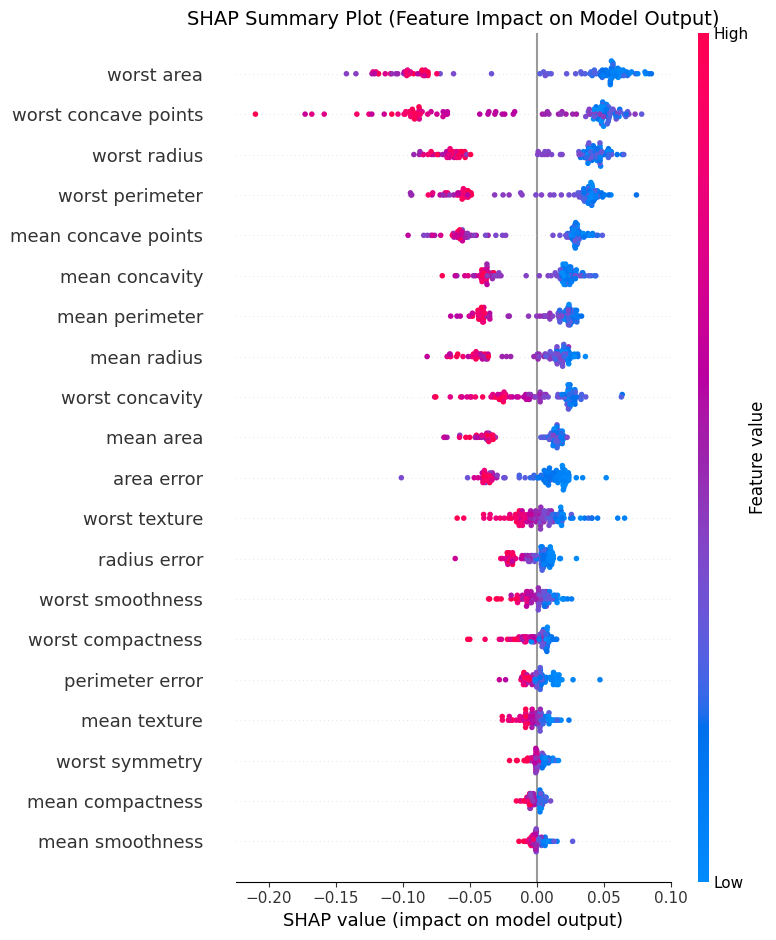

/tmp/ipykernel_2559/3614339834.py:18: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_class1, X_test, plot_type="bar", show=False)


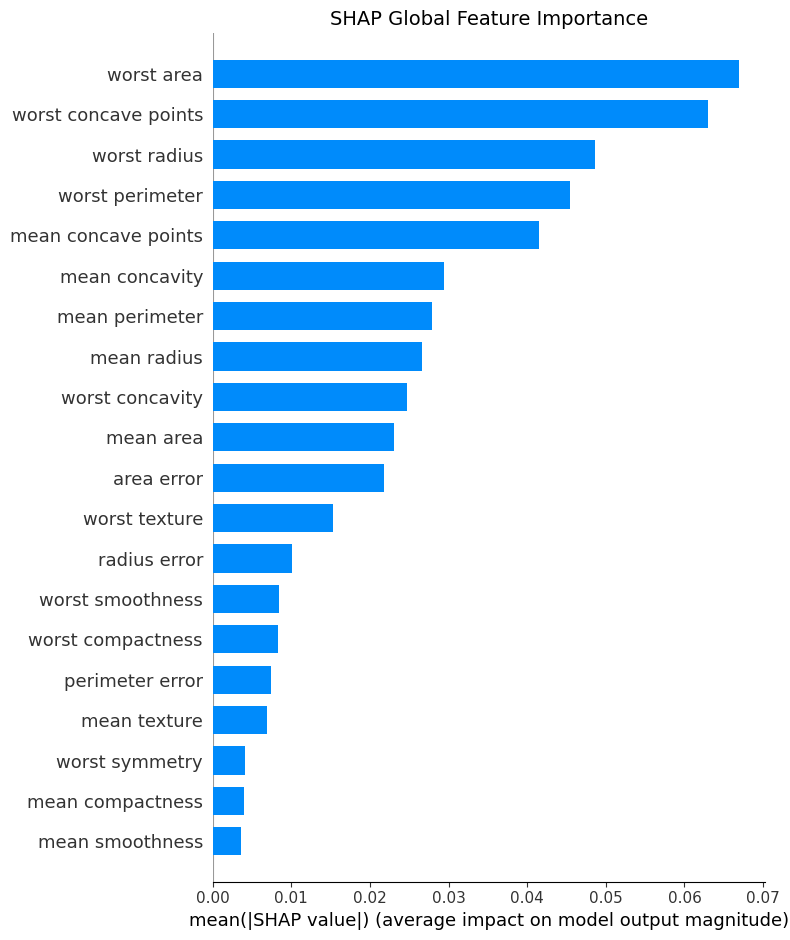

In [6]:
# Initialize SHAP Explainer (works reliably across modern SHAP versions)
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

# For binary classification, shap_values contains explanations for both classes.
# We slice for class 1 (Benign/Target class) across all samples: shape becomes (n_samples, n_features)
shap_vals_class1 = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

# 1. SHAP Summary Plot (Bee Swarm Plot)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_vals_class1, X_test, show=False)
plt.title("SHAP Summary Plot (Feature Impact on Model Output)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. SHAP Feature Importance Bar Plot
plt.figure(figsize=(12, 6))
shap.summary_plot(shap_vals_class1, X_test, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance", fontsize=14)
plt.tight_layout()
plt.show()

### 4. Local Interpretability & Feature Interactions (SHAP)
While global plots show overall trends, local interpretability explains *individual* predictions.
- **SHAP Force Plots / Waterfall Plots:** Explain why a specific patient was classified as malignant or benign.
- **SHAP Dependence Plots:** Illustrate how a feature affects predictions while capturing interactions with a second feature.

Explaining prediction for test sample index 0:
True Label: Malignant
Model Prediction: Malignant


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

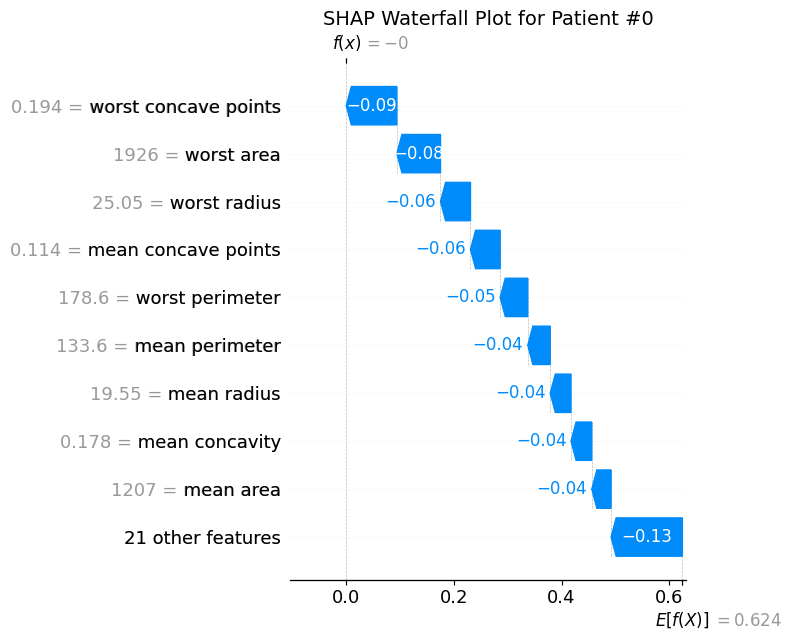

<Figure size 1000x600 with 0 Axes>

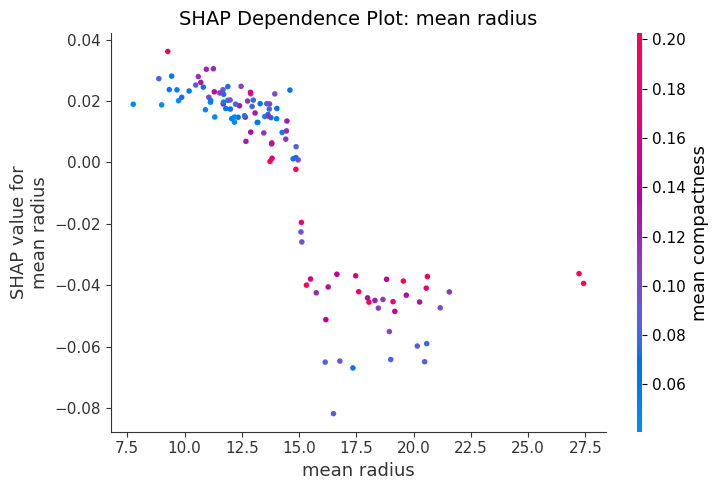

In [9]:
# Select a single instance from the test set to explain locally (e.g., index 0)
instance_idx = 0
print(f"Explaining prediction for test sample index {instance_idx}:")
print(f"True Label: {'Benign' if y_test.iloc[instance_idx] == 1 else 'Malignant'}")
print(f"Model Prediction: {'Benign' if y_pred[instance_idx] == 1 else 'Malignant'}")

# SHAP Waterfall Plot for Local Explanation targeting class 1 specifically
plt.figure(figsize=(10, 6))
# If shap_values has 3 dimensions (samples, features, classes), select [instance_idx, :, 1]
single_explanation = shap_values[instance_idx, :, 1] if len(shap_values.shape) == 3 else shap_values[instance_idx]

shap.waterfall_plot(single_explanation, show=False)
plt.title(f"SHAP Waterfall Plot for Patient #{instance_idx}", fontsize=14)
plt.tight_layout()
plt.show()

# SHAP Dependence Plot for the top feature
top_feature = X.columns[0]
plt.figure(figsize=(10, 6))
shap.dependence_plot(top_feature, shap_vals_class1.values if hasattr(shap_vals_class1, 'values') else shap_vals_class1, X_test, show=False)
plt.title(f"SHAP Dependence Plot: {top_feature}", fontsize=14)
plt.tight_layout()
plt.show()

### 5. Local Interpretable Model-agnostic Explanations (LIME)
To complement SHAP, we implement **LIME**. LIME perturbs the input around a specific instance, observes how predictions change, and fits a simple linear surrogate model locally. This verifies our SHAP findings using a completely different mathematical formulation.

In [18]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Initialize LIME Tabular Explainer
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X.columns.tolist(),
    class_names=['Malignant', 'Benign'],
    mode='classification',
    random_state=RANDOM_SEED
)

# Explain the prediction for the same test instance
exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[instance_idx],
    predict_fn=rf_model.predict_proba,
    num_features=5
)

# Display LIME explanation visually in the Jupyter notebook (called without arguments)
exp.show_in_notebook()

# Also print textual summary of LIME explanation for robust reporting
print("\n--- LIME Explanation Feature Weights ---")
for feature_weight in exp.as_list():
    print(f"{feature_weight[0]}: {feature_weight[1]:.4f}")


--- LIME Explanation Feature Weights ---
worst concave points > 0.16: -0.1457
worst area > 1033.50: -0.1401
worst radius > 18.55: -0.1040
worst perimeter > 124.95: -0.0786
mean concave points > 0.07: -0.0619


### 6. Discussion: Real-World Applications, Trust, and Accountability

#### Improving Trust and Clinical Decision-Making
In medical diagnostics, a black-box AI model—regardless of high accuracy—will face skepticism from doctors and patients. XAI bridges this gap:
1. **Clinical Validation:** If the model flags a tumor as malignant, clinicians can review the SHAP waterfall plot to verify that key biological markers (e.g., cell radius, perimeter, concavity) drove the decision, aligning with established oncology guidelines.
2. **Detecting Bias & Artifacts:** XAI helps uncover hidden data artifacts. If a model relies on irrelevant hospital metadata rather than physiological features, XAI exposes it before deployment.
3. **Accountability & Regulatory Compliance:** Frameworks like the EU AI Act mandate explainability in high-risk AI domains. Providing localized explanations ensures legal compliance and clear liability attribution.